### Step 1: Importing libraries

In [27]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

### Step 2: Load and Inspecting the  dataset

In [2]:
kenya_mobile_money_data = pd.read_csv(r"../data/clean/kenya_mobile_money_transactions.csv", parse_dates=["transaction_timestamp"])

In [3]:
kenya_mobile_money_data.head()

,transaction_id,transaction_timestamp,customer_id,customer_name,gender,age,county,phone_number,channel,transaction_type,merchant_category,device_type,amount_kes,transaction_fee_kes,balance_after_kes,status
0,TXN0000142,2024-01-01 07:51:00,CUST00093,Achieng Omollo,Female,43,Trans Nzoia,722032123,M-Pesa,Buy Goods (Till),Hardware,Feature Phone,16624.41,62,41335.52,Completed
1,TXN0002262,2024-01-01 07:54:00,CUST00401,Rotich Kiplagat,Male,52,Turkana,701747827,M-Pesa,Deposit Cash,NaN,Android,24541.89,0,181880.31,Completed
2,TXN0004820,2024-01-01 08:07:00,CUST00406,Atieno Wabwire,Male,20,Meru,723381770,M-Pesa,Buy Goods (Till),Hardware,Android,2745.80,33,73354.11,Completed
3,TXN0003825,2024-01-01 08:35:00,CUST00146,Gitau Karanja,Male,71,Nairobi,722934999,Airtel Money,Send Money,NaN,Android,13159.67,62,9511.86,Completed
4,TXN0003076,2024-01-01 09:02:00,CUST00253,Njeri Barasa,Male,63,Kisumu,710755182,M-Pesa,Send Money,NaN,Android,28359.70,100,222644.38,Completed


In [4]:
kenya_mobile_money_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   transaction_id         6000 non-null   str           
 1   transaction_timestamp  6000 non-null   datetime64[us]
 2   customer_id            6000 non-null   str           
 3   customer_name          6000 non-null   str           
 4   gender                 6000 non-null   str           
 5   age                    6000 non-null   int64         
 6   county                 6000 non-null   str           
 7   phone_number           6000 non-null   int64         
 8   channel                6000 non-null   str           
 9   transaction_type       6000 non-null   str           
 10  merchant_category      2449 non-null   str           
 11  device_type            6000 non-null   str           
 12  amount_kes             6000 non-null   float64       
 13  transaction_fe

__Checking for Missing Values__

In [5]:
kenya_mobile_money_data.isna().sum()

transaction_id              0
transaction_timestamp       0
customer_id                 0
customer_name               0
gender                      0
age                         0
county                      0
phone_number                0
channel                     0
transaction_type            0
merchant_category        3551
device_type                 0
amount_kes                  0
transaction_fee_kes         0
balance_after_kes           0
status                      0
dtype: int64

### Step 3: Exploratory Data Analysis

#### 1. Monthly revenue trend and month-over-month growth
Compute total **fee revenue** (`transaction_fee_kes`) per calendar month, then
add a column showing the **month-over-month % change**. Which month grew fastest?

In [6]:
completed = kenya_mobile_money_data[kenya_mobile_money_data["status"]== "Completed"]
completed

,transaction_id,transaction_timestamp,customer_id,customer_name,gender,age,county,phone_number,channel,transaction_type,merchant_category,device_type,amount_kes,transaction_fee_kes,balance_after_kes,status
0,TXN0000142,2024-01-01 07:51:00,CUST00093,Achieng Omollo,Female,43,Trans Nzoia,722032123,M-Pesa,Buy Goods (Till),Hardware,Feature Phone,16624.41,62,41335.52,Completed
1,TXN0002262,2024-01-01 07:54:00,CUST00401,Rotich Kiplagat,Male,52,Turkana,701747827,M-Pesa,Deposit Cash,NaN,Android,24541.89,0,181880.31,Completed
2,TXN0004820,2024-01-01 08:07:00,CUST00406,Atieno Wabwire,Male,20,Meru,723381770,M-Pesa,Buy Goods (Till),Hardware,Android,2745.80,33,73354.11,Completed
3,TXN0003825,2024-01-01 08:35:00,CUST00146,Gitau Karanja,Male,71,Nairobi,722934999,Airtel Money,Send Money,NaN,Android,13159.67,62,9511.86,Completed
4,TXN0003076,2024-01-01 09:02:00,CUST00253,Njeri Barasa,Male,63,Kisumu,710755182,M-Pesa,Send Money,NaN,Android,28359.70,100,222644.38,Completed
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5995,TXN0002555,2024-12-31 16:43:00,CUST00669,Kirui Njuguna,Male,65,Kiambu,111726719,Airtel Money,Airtime Purchase,NaN,Android,447.37,0,48148.09,Completed
5996,TXN0002692,2024-12-31 17:15:00,CUST00395,Nyambura Odhiambo,Male,36,Machakos,759145902,M-Pesa,Send Money,NaN,Android,11135.76,62,87648.22,Completed
5997,TXN0003223,2024-12-31 17:52:00,CUST00036,Akinyi Amollo,Female,64,Turkana,768858742,M-Pesa,Airtime Purchase,NaN,Android,730.68,0,118570.69,Completed
5998,TXN0000086,2024-12-31 20:56:00,CUST00319,Akinyi Wanjala,Female,20,Garissa,759514168,Airtel Money,Buy Goods (Till),Supermarket,Feature Phone,17941.80,55,51920.45,Completed


In [7]:
# Monthly revenue trend
monthly_revenue = (completed.set_index("transaction_timestamp").resample("ME")["transaction_fee_kes"].sum().reset_index())

In [8]:
print(monthly_revenue)

   transaction_timestamp  transaction_fee_kes
0             2024-01-31                33876
1             2024-02-29                31452
2             2024-03-31                33417
3             2024-04-30                33705
4             2024-05-31                37474
5             2024-06-30                31925
6             2024-07-31                33923
7             2024-08-31                32716
8             2024-09-30                32513
9             2024-10-31                34355
10            2024-11-30                33452
11            2024-12-31                33501


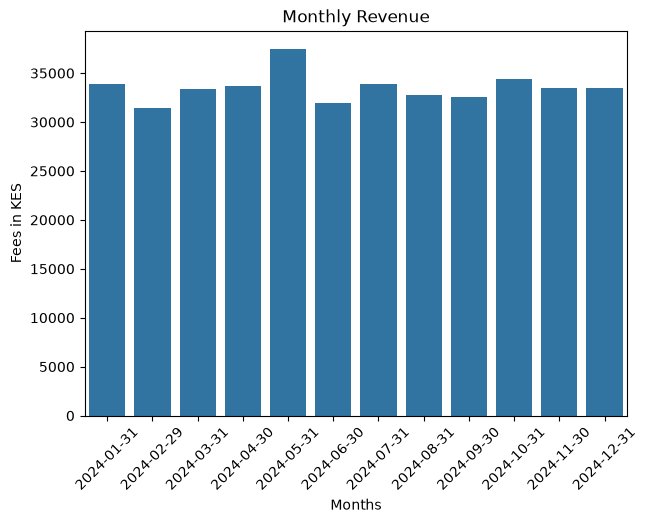

In [9]:
# Visualizing monthly revenue 
plt.figure(figsize=(7,5))
sns.barplot(data = monthly_revenue, x = "transaction_timestamp", y= "transaction_fee_kes")
plt.title("Monthly Revenue")
plt.xlabel("Months")
plt.ylabel("Fees in KES")
plt.xticks(rotation =45)

plt.show()


In [10]:
# Month over month percentage change
monthly_revenue["monthly_pct_growth"] = (monthly_revenue["transaction_fee_kes"].pct_change()*100)
monthly_revenue

,transaction_timestamp,transaction_fee_kes,monthly_pct_growth
0,2024-01-31,33876,NaN
1,2024-02-29,31452,-7.155508
2,2024-03-31,33417,6.247615
3,2024-04-30,33705,0.861837
4,2024-05-31,37474,11.182317
5,2024-06-30,31925,-14.807600
6,2024-07-31,33923,6.258418
7,2024-08-31,32716,-3.558058
8,2024-09-30,32513,-0.620492
9,2024-10-31,34355,5.665426


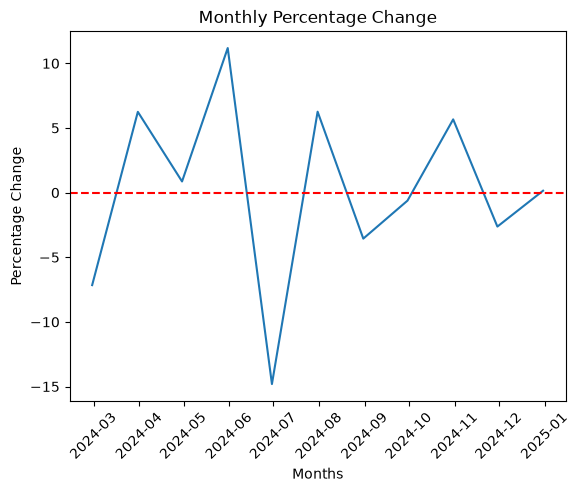

In [11]:
# Visualizing the monthly pct change
plt.Figure(figsize=(7,5))

sns.lineplot(data= monthly_revenue, x="transaction_timestamp", y="monthly_pct_growth")
plt.axhline(y = 0, color = "red", linestyle = "--")
plt.title("Monthly Percentage Change")
plt.xlabel("Months")
plt.ylabel("Percentage Change")
plt.xticks(rotation = 45)

plt.show()

__Conclusion__
- June had the highest month over month positive percentage change
- July had the highest negative month over month percentage change

In [12]:
kenya_mobile_money_data

,transaction_id,transaction_timestamp,customer_id,customer_name,gender,age,county,phone_number,channel,transaction_type,merchant_category,device_type,amount_kes,transaction_fee_kes,balance_after_kes,status
0,TXN0000142,2024-01-01 07:51:00,CUST00093,Achieng Omollo,Female,43,Trans Nzoia,722032123,M-Pesa,Buy Goods (Till),Hardware,Feature Phone,16624.41,62,41335.52,Completed
1,TXN0002262,2024-01-01 07:54:00,CUST00401,Rotich Kiplagat,Male,52,Turkana,701747827,M-Pesa,Deposit Cash,NaN,Android,24541.89,0,181880.31,Completed
2,TXN0004820,2024-01-01 08:07:00,CUST00406,Atieno Wabwire,Male,20,Meru,723381770,M-Pesa,Buy Goods (Till),Hardware,Android,2745.80,33,73354.11,Completed
3,TXN0003825,2024-01-01 08:35:00,CUST00146,Gitau Karanja,Male,71,Nairobi,722934999,Airtel Money,Send Money,NaN,Android,13159.67,62,9511.86,Completed
4,TXN0003076,2024-01-01 09:02:00,CUST00253,Njeri Barasa,Male,63,Kisumu,710755182,M-Pesa,Send Money,NaN,Android,28359.70,100,222644.38,Completed
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5995,TXN0002555,2024-12-31 16:43:00,CUST00669,Kirui Njuguna,Male,65,Kiambu,111726719,Airtel Money,Airtime Purchase,NaN,Android,447.37,0,48148.09,Completed
5996,TXN0002692,2024-12-31 17:15:00,CUST00395,Nyambura Odhiambo,Male,36,Machakos,759145902,M-Pesa,Send Money,NaN,Android,11135.76,62,87648.22,Completed
5997,TXN0003223,2024-12-31 17:52:00,CUST00036,Akinyi Amollo,Female,64,Turkana,768858742,M-Pesa,Airtime Purchase,NaN,Android,730.68,0,118570.69,Completed
5998,TXN0000086,2024-12-31 20:56:00,CUST00319,Akinyi Wanjala,Female,20,Garissa,759514168,Airtel Money,Buy Goods (Till),Supermarket,Feature Phone,17941.80,55,51920.45,Completed


#### 2. Peak transaction hours (heatmap-ready)
Build a **day-of-week × hour-of-day** matrix of transaction counts. Identify the
single busiest hour block. *(Skills: extracting hour & weekday from a timestamp,
pivoting.)*

In [13]:
completed["weekday"] = completed["transaction_timestamp"].dt.day_name()
completed["hour"] = completed["transaction_timestamp"].dt.hour

In [14]:
completed.head()

,transaction_id,transaction_timestamp,customer_id,customer_name,gender,age,county,phone_number,channel,transaction_type,merchant_category,device_type,amount_kes,transaction_fee_kes,balance_after_kes,status,weekday,hour
0,TXN0000142,2024-01-01 07:51:00,CUST00093,Achieng Omollo,Female,43,Trans Nzoia,722032123,M-Pesa,Buy Goods (Till),Hardware,Feature Phone,16624.41,62,41335.52,Completed,Monday,7
1,TXN0002262,2024-01-01 07:54:00,CUST00401,Rotich Kiplagat,Male,52,Turkana,701747827,M-Pesa,Deposit Cash,NaN,Android,24541.89,0,181880.31,Completed,Monday,7
2,TXN0004820,2024-01-01 08:07:00,CUST00406,Atieno Wabwire,Male,20,Meru,723381770,M-Pesa,Buy Goods (Till),Hardware,Android,2745.80,33,73354.11,Completed,Monday,8
3,TXN0003825,2024-01-01 08:35:00,CUST00146,Gitau Karanja,Male,71,Nairobi,722934999,Airtel Money,Send Money,NaN,Android,13159.67,62,9511.86,Completed,Monday,8
4,TXN0003076,2024-01-01 09:02:00,CUST00253,Njeri Barasa,Male,63,Kisumu,710755182,M-Pesa,Send Money,NaN,Android,28359.70,100,222644.38,Completed,Monday,9


__Pivot Table__

In [15]:
pivot_table = completed.pivot_table(
    index = "hour",
    columns= "weekday",
    values = "transaction_id",
    aggfunc= "count",
    fill_value= 0
)

pivot_table

weekday,Friday,Monday,Saturday,Sunday,Thursday,Tuesday,Wednesday
hour,,,,,,,
0,11,10,9,7,17,13,10
1,8,9,10,6,12,11,10
2,7,8,10,9,11,16,11
3,10,17,13,4,17,15,11
4,18,11,12,5,13,10,7
5,7,10,12,11,14,4,8
6,27,38,33,21,39,43,28
7,33,36,37,40,40,43,56
8,45,38,48,40,44,51,40


In [16]:
peak = (completed.groupby(["weekday", "hour"]).size().reset_index(name= "transactions").sort_values("transactions", ascending=False))

peak

,weekday,hour,transactions
153,Wednesday,9,69
40,Monday,16,59
151,Wednesday,7,56
107,Thursday,11,55
159,Wednesday,15,55
...,...,...,...
72,Sunday,0,7
73,Sunday,1,6
76,Sunday,4,5
75,Sunday,3,4


__Conclusion__
- `Single busiest hour clock was Wednesday at 09:00 AM`

#### 3. Top customers by value, ranked within their county
For each county, rank customers by **total amount transacted** and return the
**top 3 per county**. *(Skills: `RANK()` / `ROW_NUMBER()` partitioned by county,
or `groupby().rank()`.)*

In [17]:
completed["county"].unique()

<StringArray>
['Trans Nzoia',     'Turkana',        'Meru',     'Nairobi',      'Kisumu',
      'Nakuru',     'Bungoma',     'Mombasa',     'Garissa',    'Kakamega',
      'Kiambu',      'Migori', 'Uasin Gishu',       'Bomet',      'Kilifi',
     'Kajiado',    'Machakos',    'Homa Bay',       'Nyeri',     'Kericho']
Length: 20, dtype: str

In [18]:
completed["customer_id"].unique()

<StringArray>
['CUST00093', 'CUST00401', 'CUST00406', 'CUST00146', 'CUST00253', 'CUST00080',
 'CUST00570', 'CUST00441', 'CUST00759', 'CUST00765',
 ...
 'CUST00182', 'CUST00364', 'CUST00012', 'CUST00150', 'CUST00083', 'CUST00433',
 'CUST00513', 'CUST00787', 'CUST00133', 'CUST00444']
Length: 799, dtype: str

In [19]:
customer_totals = completed.groupby(["county","customer_id", "customer_name"])["amount_kes"].sum().reset_index()

customer_totals

,county,customer_id,customer_name,amount_kes
0,Bomet,CUST00018,Njoroge Waweru,295383.78
1,Bomet,CUST00107,Wairimu Omollo,172953.56
2,Bomet,CUST00123,Kiprop Gichuru,229925.30
3,Bomet,CUST00164,Adhiambo Wabwire,113764.81
4,Bomet,CUST00182,Kibet Wekesa,26367.93
...,...,...,...,...
794,Uasin Gishu,CUST00695,Rotich Kimani,123042.27
795,Uasin Gishu,CUST00734,Rotich Kiplagat,392892.88
796,Uasin Gishu,CUST00750,Ochieng Njoroge,195589.16
797,Uasin Gishu,CUST00763,Mwangi Otieno,416877.20


In [20]:
customer_totals["rank"] = customer_totals.groupby("county")["amount_kes"].rank(ascending = False)

top_three_per_county = customer_totals[customer_totals["rank"] <= 3]

top_three_per_county.sort_values(["county", "rank"])


,county,customer_id,customer_name,amount_kes,rank
10,Bomet,CUST00465,Mutua Musyoka,330868.23,1.0
15,Bomet,CUST00709,Kagwe Kamau,310710.67,2.0
5,Bomet,CUST00185,Wairimu Otieno,309514.15,3.0
30,Bungoma,CUST00229,Rotich Gichuru,472761.38,1.0
35,Bungoma,CUST00331,Nafula Langat,391095.20,2.0
41,Bungoma,CUST00570,Maina Chepkwony,374698.69,3.0
61,Garissa,CUST00573,Kagwe Chepkwony,366407.86,1.0
57,Garissa,CUST00388,Njoroge Kiplagat,282178.41,2.0
58,Garissa,CUST00398,Kariuki Gichuru,270122.27,3.0
82,Homa Bay,CUST00685,Njoroge Musyoka,471429.90,1.0


#### 4. 7-day rolling transaction volume
Create a daily transaction-count series, then compute the **7-day rolling
average** of daily volume. On how many days did volume exceed 1.5× its rolling
average? *(Skills: resampling to daily, rolling windows.)*

In [21]:
daily = completed.set_index("transaction_timestamp").resample("D")["transaction_id"].count()

daily

transaction_timestamp
2024-01-01    18
2024-01-02    17
2024-01-03    22
2024-01-04    13
2024-01-05    11
              ..
2024-12-27    14
2024-12-28    19
2024-12-29    15
2024-12-30    15
2024-12-31    14
Freq: D, Name: transaction_id, Length: 366, dtype: int64

In [22]:
rolling = daily.rolling(7).mean()

result = pd.DataFrame({
    "daily": daily,
    "rolling_avg": rolling
})

result["above_1.5_times"] = result["daily"] > 1.5 * result["rolling_avg"]

result

,daily,rolling_avg,above_1.5_times
transaction_timestamp,,,
2024-01-01,18,NaN,False
2024-01-02,17,NaN,False
2024-01-03,22,NaN,False
2024-01-04,13,NaN,False
2024-01-05,11,NaN,False
...,...,...,...
2024-12-27,14,13.714286,False
2024-12-28,19,15.142857,False
2024-12-29,15,14.714286,False


In [23]:
# Count of transactions
result["above_1.5_times"].sum()

np.int64(4)

### 5. Customer RFM segmentation
For every customer, compute **Recency** (days since last transaction, relative to
the dataset's max date), **Frequency** (number of transactions), and **Monetary**
(total amount). Score each into quintiles (1–5) and label the top segment as
"Champions".

__Information Needed__
- transaction_timestamp
- transaction_id
- amount_kes
- customer_id


In [29]:
latest = completed["transaction_timestamp"].max()
rfm = completed.groupby("customer_id").agg(
    Recency = ("transaction_timestamp", lambda x: (latest -x.max()).days),
    Frequency = ("transaction_id", "count"),
    Monetary = ("amount_kes", "sum")
)

rfm["R"] = pd.qcut(rfm["Recency"],5, labels=[5,4,3,2,1])
rfm["F"] = pd.qcut(rfm["Frequency"].rank(method = "first"), 5, labels=[1,2,3,4,5])
rfm["M"] = pd.qcut(rfm["Monetary"],5, labels=[1,2,3,4,5])

rfm["segment"] = np.where((rfm["R"] == 5) & 
                          (rfm["F"]== 5) &
                          (rfm["M"] == 5),
                          "Champions", "Other"
                          )

rfm.head()


,Recency,Frequency,Monetary,R,F,M,segment
customer_id,,,,,,,
CUST00001,33,5,104013.95,3,1,1,Other
CUST00002,10,12,437940.87,5,5,5,Champions
CUST00003,111,8,248563.66,1,3,4,Other
CUST00004,110,9,182903.23,1,4,3,Other
CUST00005,195,6,183894.74,1,2,3,Other
